In [11]:
# from sklearn.tree import DecisionTreeRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "pyproject.toml").is_file():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the project root with pyproject.toml")

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "corrosion_data_clean.parquet"
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Clean data not found at {DATA_PATH}. Run notebooks/data_cleaning.ipynb first."
    )

data = pd.read_parquet(DATA_PATH)
data.head()

,paper_id,alloy,temperature_c,exposure_time_h,flow_m_per_s,corrosion_rate_um_per_year,headgas_air,headgas_n2,headgas_o2_sealed_loop,ni_wt_pct,...,n_wt_pct,nb_wt_pct,co_wt_pct,mo_wt_pct,al_wt_pct,ti_wt_pct,cu_wt_pct,w_wt_pct,p_wt_pct,s_wt_pct
0,P002,Inconel 625,560,750.0,1.7,0.0,1,0,0,54.95,...,0.00,4.15,1.0,10.0,0.4,0.4,0.0,0.0,0.0,0.0
1,P002,Haynes 230,560,750.0,1.7,0.8,1,0,0,52.10,...,0.00,0.50,5.0,2.0,0.3,0.1,0.0,14.0,0.0,0.0
2,P002,Inconel 617,560,750.0,1.7,0.8,1,0,0,43.25,...,0.00,0.00,15.0,10.0,1.5,0.6,0.5,0.0,0.0,0.0
3,P002,HR6W,560,750.0,1.7,3.3,1,0,0,34.35,...,0.00,0.35,0.0,0.0,0.0,0.2,0.0,8.0,0.0,0.0
4,P002,Sanicro25,560,750.0,1.7,14.2,1,0,0,25.00,...,0.23,0.50,1.5,0.0,0.0,0.0,3.0,3.6,0.0,0.0


In [12]:
TARGET_COL = "corrosion_rate_um_per_year"
CONDITION_COLS = [
    "temperature_c",
    "exposure_time_h",
    "flow_m_per_s",
]
HEADGAS_COLUMNS = [
    "headgas_air",
    "headgas_n2",
    "headgas_o2_sealed_loop",
]
COMPOSITION_COLUMNS = [column for column in data if column.endswith("_wt_pct")]

## Normalization

In [ ]:
unnorm_rawtarget_data = data.copy()

# Log-transform the target variable to stabilize variance
unnorm_logtarget_data = data.copy()
unnorm_logtarget_data[TARGET_COL] = unnorm_logtarget_data[TARGET_COL].apply(lambda x: np.log1p(x))

# Standardize and normalize the features
norm_rawtarget_data = data.copy()
# Standardize the condition columns
for column in CONDITION_COLS: 
    mean = norm_rawtarget_data[column].mean()
    std = norm_rawtarget_data[column].std()
    norm_rawtarget_data[column] = (norm_rawtarget_data[column] - mean) / std
# Normalize the composition columns to sum to 1
for column in COMPOSITION_COLUMNS:
    norm_rawtarget_data[column] = norm_rawtarget_data[column].transform(lambda x: x/100) # TODO: Verify if this is the correct normalization formula

# Log-transform the target variable in the normalized dataset
norm_logtarget_data = norm_rawtarget_data.copy()
norm_logtarget_data[TARGET_COL] = norm_logtarget_data[TARGET_COL].apply(lambda x: np.log1p(x))


def random_data_split(data: pd.DataFrame, train_frac: float = 0.8, random_state: int = 42) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Randomly split the data into training and testing sets.

    Args:
        data (pd.DataFrame): The input data to split.
        train_frac (float): The fraction of the data to use for training.
        random_state (int): The seed for the random number generator.
    
    Returns:
        pd.DataFrame: The training set.
        pd.DataFrame: The testing set.
    """
    np.random.seed(random_state)
    shuffled_indices = np.random.permutation(len(data))
    train_size = int(len(data) * train_frac)
    train_indices = shuffled_indices[:train_size]
    test_indices = shuffled_indices[train_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

def xy_data_split(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """
    Split the data into features (X) and target (y).

    Args: 
        data (pd.DataFrame): The input data to split.

    Returns:
        pd.DataFrame: The features (X).
        pd.Series: The target (y).
    """
    X = data[CONDITION_COLS + HEADGAS_COLUMNS + COMPOSITION_COLUMNS]
    y = data[TARGET_COL]
    return X, y

# Picking a Dataset

In [ ]:
# Code here

## Grid Search

Documentation for grid search can be found [here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor


rfr = RandomForestRegressor(random_state=42)

train_data, test_data = random_data_split(data=norm_logtarget_data)
X_train, y_train = xy_data_split(train_data)
X_test, y_test = xy_data_split(test_data)

grid_params = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
}
grid_search = GridSearchCV(
    estimator=rfr,
    param_grid=grid_params,
    cv=5,
    n_jobs=-1,
    scoring="neg_mean_squared_error", # mean squared error
)
grid_search.fit(
    X_train,
    y_train
)
test_score = grid_search.score(X_test, y_test)
print("Best parameters found: ", grid_search.cv_results_['params'][grid_search.best_index_])
print("Best score found: ", grid_search.best_score_)
print("Test score: ", test_score)


Best parameters found:  {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Best score found:  -0.6845037916739056
Test score:  -0.4973518672560757


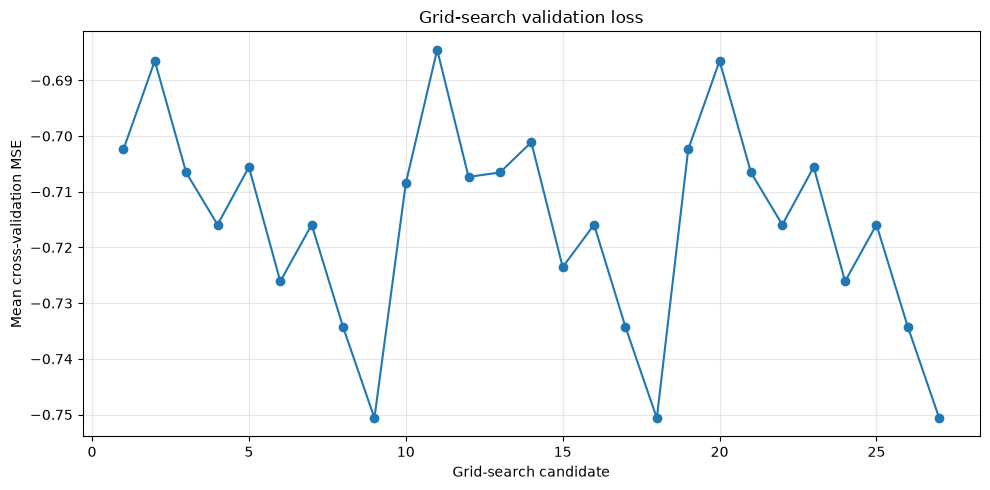

In [19]:
results = pd.DataFrame(grid_search.cv_results_)
loss = results["mean_test_score"]

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(loss) + 1), loss, marker="o")
plt.xlabel("Grid-search candidate")
plt.ylabel("Mean cross-validation MSE")
plt.title("Grid-search validation loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()